In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 01 · Descarga y controles de calidad

**Pregunta:** ¿los datos que vamos a analizar son los que creemos?

ERA5 es el reanálisis del ECMWF: un modelo del tiempo que asimila observaciones (satélites, radiosondas, estaciones)
y reconstruye el estado de la atmósfera hora a hora desde 1940 en una malla de 0,25° (~25 km).

**¿Por qué no la API directamente?** La API gratuita de Open-Meteo pesa cada petición como
`ubicaciones × días/14 × variables/10`. 45 años × 22 ciudades × 7 variables ≈ 25 000 llamadas, y el límite es
10 000 por día (y lo comparten otras sesiones en la misma IP). Open-Meteo publica el mismo ERA5 en **AWS Open Data**
(`s3://openmeteo`) en su formato `.om`, que se lee por rangos HTTP: solo bajan los bytes de cada punto.
La API se usa para dos cosas pequeñas: saber qué celda usa Open-Meteo para cada ciudad y **verificar** que mi
agregación diaria da lo mismo que la suya.

## 1. Celdas de ERA5 para cada punto

In [2]:
celdas = pd.read_csv(config.CELDAS)
celdas[["punto", "region", "altitud", "lat_celda", "lon_celda", "altitud_celda", "dist_km", "celda_mar"]]

,punto,region,altitud,lat_celda,lon_celda,altitud_celda,dist_km,celda_mar
0,Guayaquil,Costa,4,-2.250,-80.000,67.000,12.420,False
1,Manta,Costa,6,-1.000,-80.750,58.000,5.852,False
2,Esmeraldas,Costa,15,1.000,-79.500,81.000,17.271,False
3,Machala,Costa,6,-3.250,-80.000,60.000,5.074,False
4,Portoviejo,Costa,53,-1.000,-80.500,152.000,7.888,False
5,Salinas,Costa,5,-2.250,-80.750,26.000,23.438,False
6,Santo Domingo,Costa,550,-0.250,-79.250,417.000,8.685,False
7,Quito,Sierra,2850,-0.250,-78.500,"2,863.000",8.606,False
8,Cuenca,Sierra,2560,-3.000,-79.000,"3,234.000",11.134,False
9,Ambato,Sierra,2580,-1.250,-78.500,"3,155.000",13.008,False


* La API elige una celda de **tierra con altitud parecida** (no siempre la más cercana): Salinas usa una celda a 23 km.
* En la Sierra la altitud media de la celda difiere mucho de la ciudad (Riobamba: 2 754 m vs 3 684 m). La temperatura
  se corrige con un gradiente de −6,5 °C/km, la misma idea que el *downscaling* de Open-Meteo.
* En Galápagos las islas son más pequeñas que una celda: ERA5 las trata como **mar** (`celda_mar = True`).
  Eso tendrá consecuencias en la validación (notebook 06).

## 2. Bloques descargados (caché reanudable)

In [3]:
from clima_ecuador import descarga
bloques = descarga.bloques()
print(len(bloques), "bloques por variable:", bloques[0]["nombre"], "…", bloques[41]["nombre"], "+",
      len(bloques) - 42, "trozos de 504 h desde", bloques[42]["inicio"].date())
archivos = sorted(config.ERA5_CRUDO.glob("*/*.parquet"))
print(len(archivos), "archivos ·", round(sum(a.stat().st_size for a in archivos) / 1e6), "MB en data/raw/era5")
reporte("calidad_solape.csv")

95 bloques por variable: year_1980 … year_2021 + 53 trozos de 504 h desde 2021-12-23
665 archivos · 117 MB en data/raw/era5


,variable,bloques,horas_solapadas,max_dif_solape
0,temperature_2m,95,216,0.050
1,dew_point_2m,95,216,0.050
2,precipitation,95,216,0.100
3,shortwave_radiation,95,216,1.000
4,wind_u_component_10m,95,216,0.100
5,wind_v_component_10m,95,216,0.100
6,wind_gusts_10m,95,216,7.100


El último `year_2021.om` y el primer trozo de 2022 se solapan 216 horas: coinciden salvo redondeo
(0,05 °C en temperatura; las ráfagas difieren hasta 7 m/s en alguna hora). Se queda el valor del archivo anual.

## 3. Controles sobre 11,8 millones de filas horarias

In [4]:
print(json.dumps(R["calidad"], indent=1, ensure_ascii=False))
reporte("calidad_rangos.csv")

{
 "pct_completo_min": 100.0,
 "saltos": 0,
 "duplicadas": 0,
 "fuera_de_rango": 0,
 "rachas_pegadas": 0,
 "hora_pico_radiacion": [
  12,
  13
 ],
 "radiacion_medianoche_max": 0.0,
 "viento_espurio_horas": 209,
 "viento_espurio_pct": 0.001765970840357081,
 "viento_espurio_horas_utc": {
  "9": 126,
  "8": 69,
  "6": 8
 },
 "inconsistencias_diarias": 0
}


,variable,minimo,maximo,limite_bajo,limite_alto,fuera
0,temp,0.941,38.299,-15,45,0
1,punto_rocio,-17.905,29.549,-40,35,0
2,precip,0.000,32.800,0,150,0
3,radiacion,0.000,"1,208.000",0,1400,0
4,viento,0.000,112.681,0,200,0
5,rafagas,1.080,103.680,0,300,0
6,humedad,4.630,100.000,0,100,0


**Hallazgo: picos de viento espurios.** En 209 horas (0,002 %) el viento medio supera a la ráfaga máxima de la
misma hora por más de 20 km/h (en Guayaquil llega a 255 km/h con ráfagas de 17 km/h). Es físicamente imposible y
**195 de 209 caen a las 08–09 UTC**, lo que apunta a un artefacto de las componentes u/v del reanálisis, no a
tormentas. Se anulan esas horas (el resto del día sigue sirviendo).

In [5]:
reporte("calidad_viento_espurio.csv").sort_values("viento", ascending=False).head(8)

,punto,hora_utc,viento,rafagas
77,Guayaquil,2009-03-03 09:00:00,254.731,16.560
136,Guayaquil,2014-04-26 09:00:00,222.368,12.960
67,Guayaquil,2009-03-03 08:00:00,169.416,17.280
126,Guayaquil,2014-04-26 08:00:00,138.776,13.680
160,Ambato,2016-11-12 09:00:00,134.569,14.400
1,Guayaquil,1980-03-30 08:00:00,131.301,14.760
6,Guayaquil,1980-03-30 09:00:00,129.341,13.320
193,Latacunga,2022-04-20 09:00:00,113.931,10.440


In [6]:
reporte("calidad_viento_espurio_por_hora.csv")

,hora_utc,horas
0,5,2
1,6,8
2,7,4
3,8,69
4,9,126


## 4. ¿Mi agregación diaria es igual a la de la API?

In [7]:
reporte("calidad_api.csv")

,variable,variable_api,dias,dif_media,dif_abs_media,dif_abs_p99,correlacion
0,tmed_celda,temperature_2m_mean,16060,-0.001,0.025,0.050,1.000
1,tmax_celda,temperature_2m_max,16060,-0.056,0.056,0.300,1.000
2,tmin_celda,temperature_2m_min,16060,0.054,0.056,0.400,1.000
3,precip,precipitation_sum,16060,-0.000,0.000,0.000,1.000
4,humedad,relative_humidity_2m_mean,16060,-0.003,0.251,0.500,0.999
5,viento_max,wind_speed_10m_max,16060,-0.015,0.039,0.050,0.988
6,radiacion,shortwave_radiation_sum,16060,-0.000,0.000,0.000,1.000


2 años (2015 y 2023) × 22 ciudades = 16 060 días, pidiendo a la API **la misma celda** (`cell_selection=nearest`)
y sin corrección de altitud (`elevation=nan`):

* **Lluvia y radiación: diferencia 0,000.** Pero solo después de entender la convención: la lluvia de la hora *t* es
  la que cayó en la hora que **termina** en *t*, así que el día D suma de 01:00 a 24:00. Sumando de 00:00 a 23:00 la
  diferencia media era 0,15 mm/día en Quito y 0,60 en Guayaquil.
* **Tmed: 0,025 °C** (la API redondea a 0,1 °C). Tmáx y Tmín de la API son ~0,06 °C más extremas: es coherente con
  que la API use extremos sub-horarios; mi Tmáx es el máximo de 24 valores horarios.
* **Humedad: 0,25 %** (la API redondea a enteros). **Viento: r = 0,988** porque la API conserva los picos espurios.
* Un tropiezo útil: con `elevation=nan` la API elige **otra celda** en Esmeraldas, Salinas e Ibarra (no hay altitud
  de referencia para buscar una celda parecida). Por eso la muestra se pide en el centro de la celda exacta.

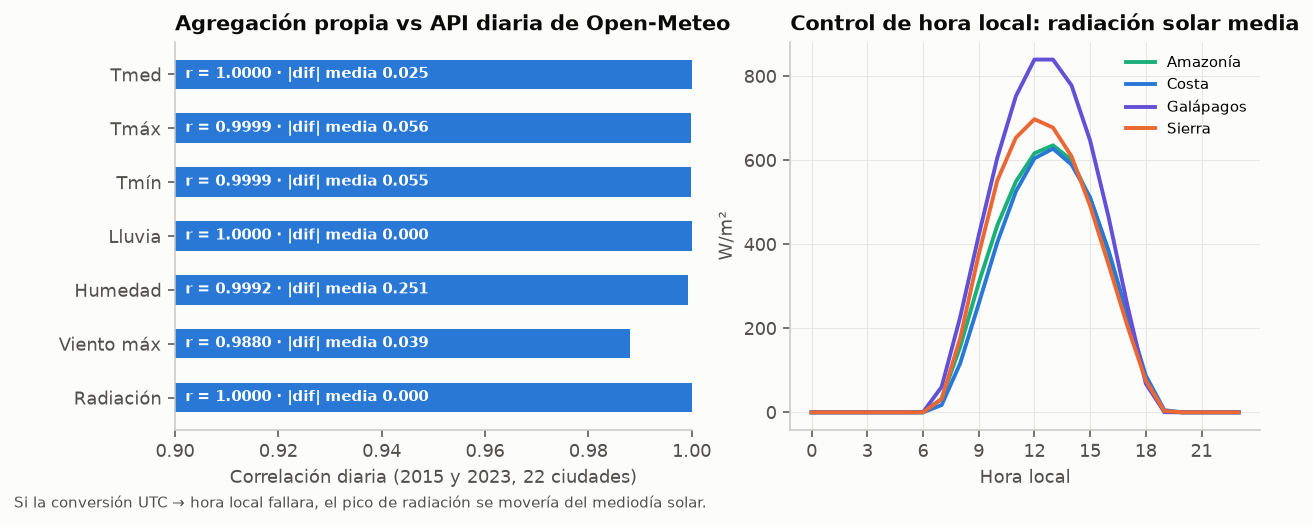

In [8]:
figura("02_calidad.png")

El pico de radiación cae a las 12–13 h locales en las 4 regiones (en Galápagos con UTC−6): la conversión de
hora UTC a hora local es correcta.

## 5. Resultado: series diarias completas

In [9]:
diario = pd.read_parquet(config.DIARIO)
print(f"{len(diario):,} días-punto · {diario['punto'].nunique()} puntos · "
      f"{diario['fecha'].min().date()} a {diario['fecha'].max().date()}")
diario.groupby("punto").size().describe()

493,110 días-punto · 30 puntos · 1980-01-01 a 2024-12-31


count       30.000
mean    16,437.000
std          0.000
min     16,437.000
25%     16,437.000
50%     16,437.000
75%     16,437.000
max     16,437.000
dtype: float64